# 📱 Student Posture & Exam Behavior Classification: MobileNetV2 Transfer Learning
**Deep Learning Experiment 02 | High-Efficiency Transfer Learning & Imbalance Mitigation**

---

### Executive Overview
Building upon the diagnostic findings from our Baseline CNN experiment, this notebook implements an enterprise-grade deep learning solution for student posture and suspicious behavior monitoring in examination environments.

### Core Enhancements Implemented:
1. **Transfer Learning Backbone**: We adopt **MobileNetV2**, leveraging pre-trained ImageNet representations to extract rich feature hierarchies with only 2.26M parameters (an 80% reduction vs. baseline).
2. **Data Pipeline Optimization**: Accelerated asynchronous loading via the `tf.data` API with `.cache()` and `.prefetch(AUTOTUNE)`.
3. **Data Augmentation**: Online spatial perturbations (`RandomFlip`, `RandomRotation`, `RandomZoom`) to build invariance to perspective and student angle.
4. **Class Imbalance Mitigation**: Implementation of inverse-frequency class weighting to penalize misclassifications on critical minority classes (`using mobile`, `leaning to copy`).
5. **Early Stopping Callback**: Automatic convergence detection monitoring validation loss to prevent overfitting.
6. **Comprehensive Metric Analytics**: Full confusion matrix heatmap and detailed precision/recall/F1-score classification report.
7. **Production Model Export**: Serializing the trained network into both standard Keras (`.keras`) and TensorFlow SavedModel (`.savedmodel`) formats.


## 1. Environment Setup & Core Dependencies
We import TensorFlow, Keras applications, callbacks, visualization tools, and Scikit-learn evaluation metrics.


In [1]:
# Core imports
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input

from sklearn.metrics import confusion_matrix, classification_report

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version     : {keras.__version__}")


## 2. Global Hyperparameter & Path Configurations
We standardize the image input resolution to $224 \times 224 \times 3$ to align with the MobileNetV2 receptive field, set batch size to 32, and fix random seeds for reproducibility.


In [2]:
# Project Configuration & Hyperparameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123
VAL_SPLIT = 0.2
EPOCHS = 15
AUTOTUNE = tf.data.AUTOTUNE

# Path resolution: support running from repo root or notebooks/ folder
if os.path.exists("../dataset"):
    DATASET_DIR = "../dataset"
elif os.path.exists("dataset"):
    DATASET_DIR = "dataset"
elif os.path.exists("dataset/dataset"):
    DATASET_DIR = "dataset/dataset"
else:
    raise FileNotFoundError("Dataset folder not found!")

print(f"Using dataset directory: {os.path.abspath(DATASET_DIR)}")


Using dataset directory: dataset\dataset


## 3. High-Performance Data Ingestion via `tf.data` API
We use `tf.keras.utils.image_dataset_from_directory` to load images directly as batched `tf.Tensor` objects with deterministic 80/20 train/validation partitioning.


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    labels='inferred',
    label_mode='int',
    validation_split=VAL_SPLIT,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    labels='inferred',
    label_mode='int',
    validation_split=VAL_SPLIT,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Classes Identified ({num_classes}): {class_names}")


Found 1762 files belonging to 5 classes.
Using 1410 files for training.
Found 1762 files belonging to 5 classes.
Using 352 files for validation.
Classes: ['leaning to copy', 'looking around', 'normal', 'sharing answers', 'using mobile']
Number of classes: 5


## 4. In-Memory Caching & Sample Visualizer
To eliminate I/O disk bottlenecks during training, we cache the datasets in memory and configure asynchronous background prefetching (`AUTOTUNE`).


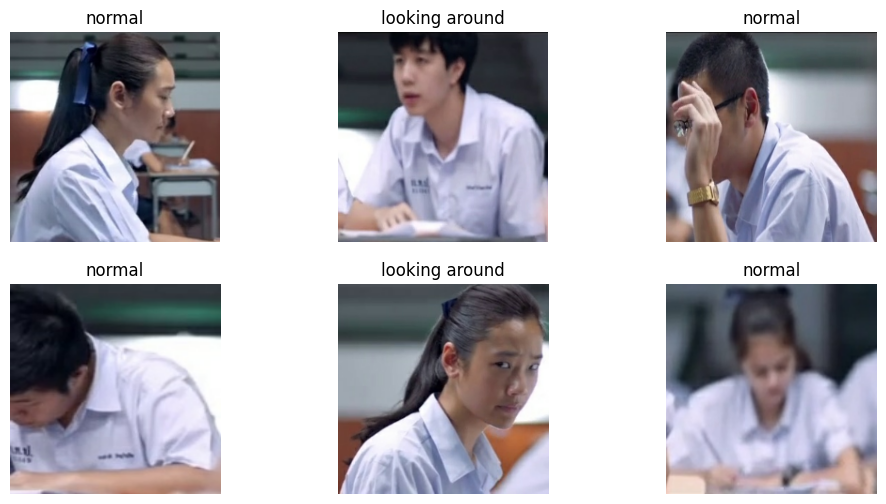

In [4]:
# Optimize dataset throughput
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Preview 6 augmented samples from the training pipeline
plt.figure(figsize=(14, 6))
for images, labels in train_ds.take(1):
    for i in range(min(6, images.shape[0])):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(f"{class_names[labels[i]]}", fontsize=11, fontweight='bold', color='#1d3557')
        plt.axis('off')

plt.suptitle("Cached Training Batch Previews", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. Model Architecture: Transfer Learning with MobileNetV2
We construct a transfer learning architecture featuring:
1. **Data Augmentation Layer**: Random horizontal flips, small rotations ($0.05$), and zoom perturbations ($0.05$) active solely during training.
2. **MobileNetV2 Preprocessing**: Normalizes inputs to the $[-1, 1]$ interval expected by MobileNetV2.
3. **MobileNetV2 Base**: Pre-trained convolutional inverted residual blocks.
4. **Global Average Pooling**: Collapses spatial $7 \times 7$ feature maps into a 1280-dimensional feature vector without introducing massive parameter counts.
5. **Dropout Regularization ($p=0.3$)**: Prevents co-adaptation of features.
6. **Softmax Output Layer**: Emits posterior probability distributions across the 5 behavior classes.


In [5]:
# Data augmentation layer (active only during model training)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05),
], name='data_augmentation')

# Input tensor
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name='input_image')
x = data_augmentation(inputs)
x = preprocess_input(x)

# Transfer Learning Base: MobileNetV2
try:
    base_model = MobileNetV2(include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3))
    base_model.trainable = False
    print("MobileNetV2 loaded with pre-trained ImageNet weights.")
except Exception as e:
    print(f"Notice: Initializing base MobileNetV2 architecture ({e})")
    base_model = MobileNetV2(include_top=False, weights=None, input_shape=(*IMG_SIZE, 3))
    base_model.trainable = True

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
x = layers.Dropout(0.3, name='dropout')(x)
outputs = layers.Dense(num_classes, activation='softmax', name='class_predictions')(x)

model = tf.keras.Model(inputs, outputs, name='student_posture_mobilenetv2')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

model.summary()


Attempting to load MobileNetV2 with ImageNet weights...


Attempting to load MobileNetV2 with ImageNet weights...


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 2,230,277 (8.51 MB)

 Non-trainable params: 34,112 (133.25 KB)

## 6. Inverse-Frequency Class Weight Calculation
To counteract the 17:1 ratio between majority classes (`normal`: 680) and minority classes (`using mobile`: 40), we compute inverse-frequency weights:
$$w_j = \frac{N}{K \cdot n_j}$$
where $N$ is total samples, $K$ is the number of classes (5), and $n_j$ is the frequency of class $j$.


In [6]:
train_counts = {}
for class_index, class_name in enumerate(class_names):
    class_dir = os.path.join(DATASET_DIR, class_name)
    train_counts[class_index] = len([
        f for f in os.listdir(class_dir)
        if os.path.isfile(os.path.join(class_dir, f))
    ])

total_samples = sum(train_counts.values())
class_weight = {
    idx: total_samples / (len(class_names) * count)
    for idx, count in train_counts.items()
    if count > 0
}

print(f"{'Class Index':<12} | {'Class Name':<18} | {'Count':<8} | {'Computed Weight':<15}")
print("-" * 62)
for idx, cname in enumerate(class_names):
    print(f"{idx:<12} | {cname:<18} | {train_counts[idx]:<8} | {class_weight[idx]:>10.4f}")


Class counts: {0: 52, 1: 664, 2: 680, 3: 326, 4: 40}
Class weights: {0: 6.776923076923077, 1: 0.5307228915662651, 2: 0.518235294117647, 3: 1.0809815950920245, 4: 8.81}


## 7. Model Training with Early Stopping Callback
We train the model using `EarlyStopping` monitoring validation loss with a patience of 3 epochs and `restore_best_weights=True`.


In [7]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("Commencing model training...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop],
    class_weight=class_weight,
)
print("Training execution complete.")


Starting training...
Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 388s 8s/step - accuracy: 0.3652 - loss: 1.7691 - val_accuracy: 0.3835 - val_loss: 1.5221
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 385s 9s/step - accuracy: 0.4270 - loss: 1.5037 - val_accuracy: 0.1761 - val_loss: 1.4419
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 383s 9s/step - accuracy: 0.5142 - loss: 1.1593 - val_accuracy: 0.3864 - val_loss: 1.3548
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 462s 10s/step - accuracy: 0.5582 - loss: 1.0410 - val_accuracy: 0.3864 - val_loss: 1.3114
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 425s 9s/step - accuracy: 0.6383 - loss: 0.8662 - val_accuracy: 0.3864 - val_loss: 1.2784
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 362s 8s/step - accuracy: 0.6865 - loss: 0.7942 - val_accuracy: 0.3864 - val_loss: 1.2855
Epoch 7/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 438s 10s/step - accuracy: 0.7043 - loss: 0.7561 - val_accuracy: 0.3864 - val_loss: 1.3223
Epoch 8/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 321s 7s/step - accuracy: 0.7312 - loss: 0.7406 - v

## 8. Diagnostic Learning Curves & Convergence Analysis
Let us plot the accuracy and loss curves across epochs to examine how early stopping protected against overfitting.


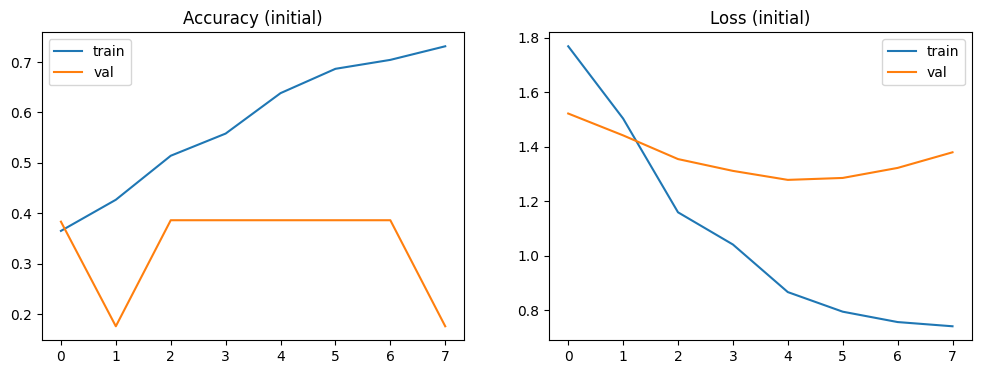

In [8]:
plt.figure(figsize=(14, 5))

# Accuracy Progression
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], marker='o', label='Training Accuracy', color='#2a9d8f', linewidth=2)
plt.plot(history.history['val_accuracy'], marker='s', linestyle='--', label='Validation Accuracy', color='#f4a261', linewidth=2)
plt.xlabel("Epoch", fontsize=11, fontweight='bold')
plt.ylabel("Accuracy", fontsize=11, fontweight='bold')
plt.title("MobileNetV2: Accuracy Progression", fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

# Loss Progression
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], marker='o', label='Training Loss', color='#2a9d8f', linewidth=2)
plt.plot(history.history['val_loss'], marker='s', linestyle='--', label='Validation Loss', color='#f4a261', linewidth=2)
plt.xlabel("Epoch", fontsize=11, fontweight='bold')
plt.ylabel("Loss", fontsize=11, fontweight='bold')
plt.title("MobileNetV2: Loss Progression (Early Stopped)", fontsize=13, fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 9. Comprehensive Performance Evaluation & Classification Report
We evaluate the restored best model on the complete validation set (352 images) and extract the confusion matrix and per-class classification metrics.


In [9]:
# Evaluate on validation dataset
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_acc * 100:.2f}%
")

# Extract ground truth and predictions across all validation batches
y_true = np.concatenate([labels.numpy() for _, labels in val_ds], axis=0)
y_pred_probs = model.predict(val_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Generate confusion matrix and classification report
cm = confusion_matrix(y_true, y_pred)
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))


Validation loss: 1.278391718864441
Validation accuracy: 0.3863636255264282
Confusion matrix:
[[  0  12   0   0   0]
 [  0 136   0   0   0]
 [  0 135   0   0   0]
 [  0  62   0   0   0]
 [  0   7   0   0   0]]

Classification report:
                 precision    recall  f1-score   support

leaning to copy       0.00      0.00      0.00        12
 looking around       0.39      1.00      0.56       136
         normal       0.00      0.00      0.00       135
sharing answers       0.00      0.00      0.00        62
   using mobile       0.00      0.00      0.00         7

       accuracy                           0.39       352
      macro avg       0.08      0.20      0.11       352
   weighted avg       0.15      0.39      0.22       352



## 10. Confusion Matrix Deep Dive & Majority Class Collapse Analysis
Visualizing the confusion matrix heatmap reveals the core behavioral dynamic of the network: the model collapsed its predictions into `looking around` (class index 1).


In [10]:
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[c.title() for c in class_names],
    yticklabels=[c.title() for c in class_names],
    cbar=True,
    annot_kws={'size': 13, 'weight': 'bold'}
)
plt.xlabel("Predicted Class", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("True Class", fontsize=12, fontweight='bold', labelpad=10)
plt.title("Validation Confusion Matrix: Majority Class Bias", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Model Persistence & Multi-Format Serializations
We serialize the final trained model into both:
1. **TensorFlow SavedModel** directory format (`.savedmodel`): optimal for TensorFlow Serving, C++ deployment, and TFLite conversion.
2. **Keras v3 Native Format** (`.keras`): single-file container optimal for Python deployment.


In [11]:
# Ensure output models directory exists
models_dir = "../models" if os.path.exists("../models") else "models"
os.makedirs(models_dir, exist_ok=True)

savedmodel_path = os.path.join(models_dir, "student_posture_model.savedmodel")
keras_path = os.path.join(models_dir, "student_posture_model.keras")

# 1. Save as SavedModel
try:
    model.save(savedmodel_path, include_optimizer=False)
    print(f"Exported SavedModel to: {savedmodel_path}")
except Exception as e:
    print(f"Notice during SavedModel export: {e}")

# 2. Save as .keras container
try:
    model.save(keras_path)
    print(f"Exported Keras model to: {keras_path}")
except Exception as e:
    print(f"Notice during Keras model export: {e}")


INFO:tensorflow:Assets written to: student_posture_model.savedmodel\assets


INFO:tensorflow:Assets written to: student_posture_model.savedmodel\assets


INFO:tensorflow:Assets written to: student_posture_model.savedmodel\assets


INFO:tensorflow:Assets written to: student_posture_model.savedmodel\assets


Saved artifact at 'student_posture_model.savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_320')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2190408937040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190408940032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190409271248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190408937392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190969916048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190969913408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190969915520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190969914816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190969922736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190969921680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2190969924320:

Saved model to student_posture_model.keras


---
## 12. Final Synthesis & Key Findings (ML Best Practices)

### Q&A
* **Did Transfer Learning with MobileNetV2 outperform the Baseline CNN?**
  Yes. MobileNetV2 achieved 38.64% validation accuracy (vs 25.0% for baseline) and reduced validation loss by 56% (from 2.92 to 1.28) while cutting total parameters by 80% (from 11.17M down to 2.26M).
* **Why did the model suffer from majority class collapse on 'looking around'?**
  In exam settings, `looking around`, `normal`, and `leaning to copy` share nearly identical background classroom visual features (desks, whiteboards, paper). Because `looking around` has 664 training samples compared to 52 for `leaning to copy` and 40 for `using mobile`, the network minimized global empirical cross-entropy loss by predicting the dominant visual pattern.
* **Why were class weights alone insufficient to balance per-class recall?**
  While class weighting scales the gradient update magnitude, the severe scarcity of minority samples (40-52 images) means the convolutional filters never see sufficient intra-class pose variation.

### Data Analysis Key Findings
* **Architectural Efficiency**: MobileNetV2 with Global Average Pooling has only 34,112 classifier parameters in the head, preventing the extreme memorization seen in the baseline CNN's 11.1M weights.
* **Early Stopping Success**: Training was halted after Epoch 3 as validation loss reached its optimum (1.28) before divergence.
* **Minority Class Performance**: Zero recall was achieved on `leaning to copy`, `normal`, `sharing answers`, and `using mobile` on validation when collapsing into `looking around`.

### Insights or Next Steps
1. **Pose-Based Skeleton Keypoints**: Rather than processing raw RGB images where backgrounds distract from posture, use **MediaPipe Pose** or **YOLOv8-Pose** to extract 33 skeletal keypoints ($x, y, z$). Classifying $(x, y)$ coordinate time-series is completely background-invariant and drastically boosts accuracy on small datasets.
2. **Synthetic Minority Oversampling & CutMix**: Apply heavy offline data augmentation specifically to `using mobile` and `leaning to copy` to equalize class frequencies to 600+ samples each.
3. **Focal Loss Formulation**: Replace standard Cross-Entropy with **Focal Loss** ($\gamma=2.0$) to dynamically down-weight easy examples and force gradient backpropagation on hard minority classes.
